<a href="https://colab.research.google.com/github/abalonsoc/Lab-SI-sesion13-CNN/blob/main/Laboratorio_UCV_CNN_Digitos_UCI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install ucimlrepo tensorflow pandas numpy matplotlib scikit-learn -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(42)
np.random.seed(42)

print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


In [3]:
digits = fetch_ucirepo(id=80)

X = digits.data.features
y = digits.data.targets.squeeze()

print('Dimensión de X:', X.shape)
print('Dimensión de y:', y.shape)

X.head()

Dimensión de X: (5620, 64)
Dimensión de y: (5620,)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute55,Attribute56,Attribute57,Attribute58,Attribute59,Attribute60,Attribute61,Attribute62,Attribute63,Attribute64
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,0,6,14,7,1,0,0
1,0,0,10,16,6,0,0,0,0,7,...,3,0,0,0,10,16,15,3,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,0,9,14,0,0,0,0
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,0,1,15,2,0,0
4,0,0,5,14,4,0,0,0,0,0,...,12,0,0,0,4,12,14,7,0,0


In [4]:
print('Clases disponibles:', sorted(y.unique()))
print('\nDistribución de clases:')
print(y.value_counts().sort_index())


Clases disponibles: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

Distribución de clases:
class
0    554
1    571
2    557
3    572
4    568
5    558
6    558
7    566
8    554
9    562
Name: count, dtype: int64


In [5]:
X_images = X.to_numpy().reshape(-1, 8, 8, 1)
y_values = y.to_numpy().astype('int')

print('Nueva forma de X:', X_images.shape)
print('Forma de y:', y_values.shape)

Nueva forma de X: (5620, 8, 8, 1)
Forma de y: (5620,)


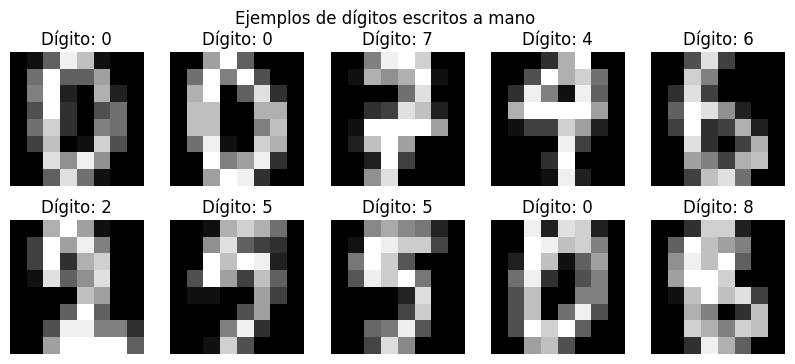

In [6]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_images[i].reshape(8, 8), cmap='gray')
    plt.title(f'Dígito: {y_values[i]}')
    plt.axis('off')

plt.suptitle('Ejemplos de dígitos escritos a mano')
plt.show()

In [7]:
X_images = X_images / 16.0

print('Valor mínimo:', X_images.min())
print('Valor máximo:', X_images.max())

Valor mínimo: 0.0
Valor máximo: 1.0


In [8]:
num_classes = 10
y_categorical = to_categorical(y_values, num_classes=num_classes)

print('Ejemplo etiqueta original:', y_values[0])
print('Ejemplo etiqueta one-hot:', y_categorical[0])

Ejemplo etiqueta original: 0
Ejemplo etiqueta one-hot: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [9]:
X_train, X_test, y_train, y_test, y_train_labels, y_test_labels = train_test_split(
    X_images,
    y_categorical,
    y_values,
    test_size=0.30,
    random_state=42,
    stratify=y_values,
)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (3934, 8, 8, 1)
X_test: (1686, 8, 8, 1)
y_train: (3934, 10)
y_test: (1686, 10)


In [10]:
model = Sequential([
    Conv2D(16, (3, 3), activation='relu', input_shape=(8, 8, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(32, (2, 2), activation='relu'),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 6, 6, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 2, 2, 32)       │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,146 (43.54 KB)

 Trainable params: 11,146 (43.54 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4480 - loss: 1.8576 - val_accuracy: 0.7751 - val_loss: 1.1032
Epoch 2/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7960 - loss: 0.7513 - val_accuracy: 0.8907 - val_loss: 0.4229
Epoch 3/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8726 - loss: 0.4392 - val_accuracy: 0.9174 - val_loss: 0.2796
Epoch 4/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9024 - loss: 0.3291 - val_accuracy: 0.9428 - val_loss: 0.2127
Epoch 5/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9221 - loss: 0.2575 - val_accuracy: 0.9479 - val_loss: 0.1721
Epoch 6/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9358 - loss: 0.2230 - val_accuracy: 0.9568 - val_loss: 0.1504
Epoch 7/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9438 - loss: 0.1906 - val_accuracy: 0.9619 - val_loss: 0.1267
Epoch 8/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9485 - loss: 0.1735 - val_accuracy: 0.9708 - val_loss:

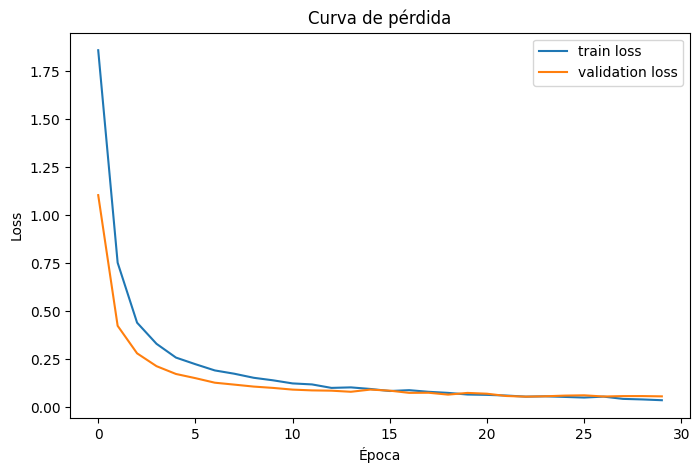

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Curva de pérdida')
plt.legend()
plt.show()

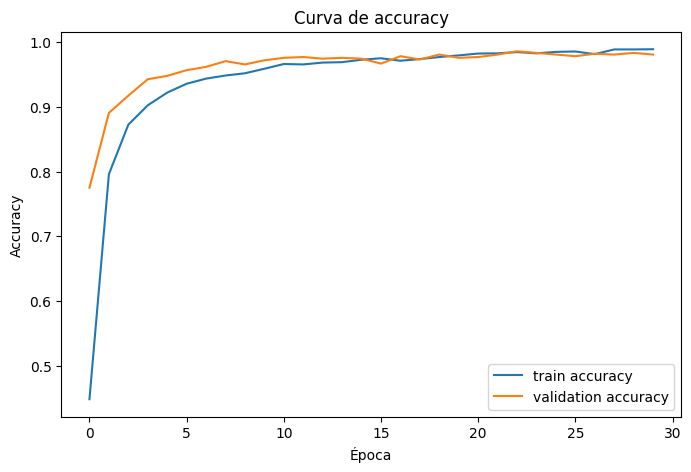

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.title('Curva de accuracy')
plt.legend()
plt.show()

In [14]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f'Test loss    : {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4f}')

Test loss    : 0.0469
Test accuracy: 0.9881


In [15]:
y_pred_prob = model.predict(X_test)
y_pred_labels = np.argmax(y_pred_prob, axis=1)

print(classification_report(y_test_labels, y_pred_labels))

53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       166
           1       0.99      0.99      0.99       171
           2       0.99      0.99      0.99       167
           3       0.99      0.97      0.98       172
           4       0.98      1.00      0.99       171
           5       0.98      0.99      0.99       167
           6       0.99      0.99      0.99       167
           7       0.98      1.00      0.99       170
           8       0.99      0.98      0.98       166
           9       0.98      0.96      0.97       169

    accuracy                           0.99      1686
   macro avg       0.99      0.99      0.99      1686
weighted avg       0.99      0.99      0.99      1686



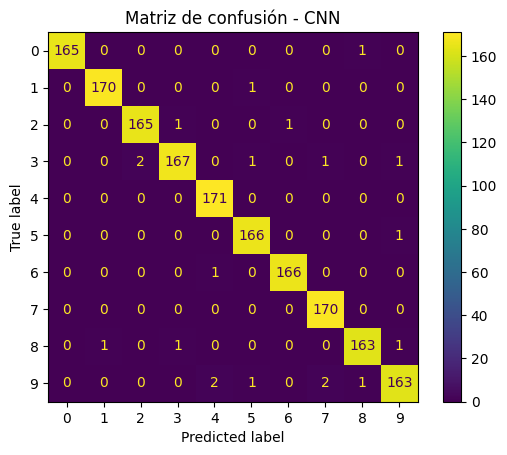

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_test_labels,
    y_pred_labels,
    display_labels=list(range(10)),
)
plt.title('Matriz de confusión - CNN')
plt.show()

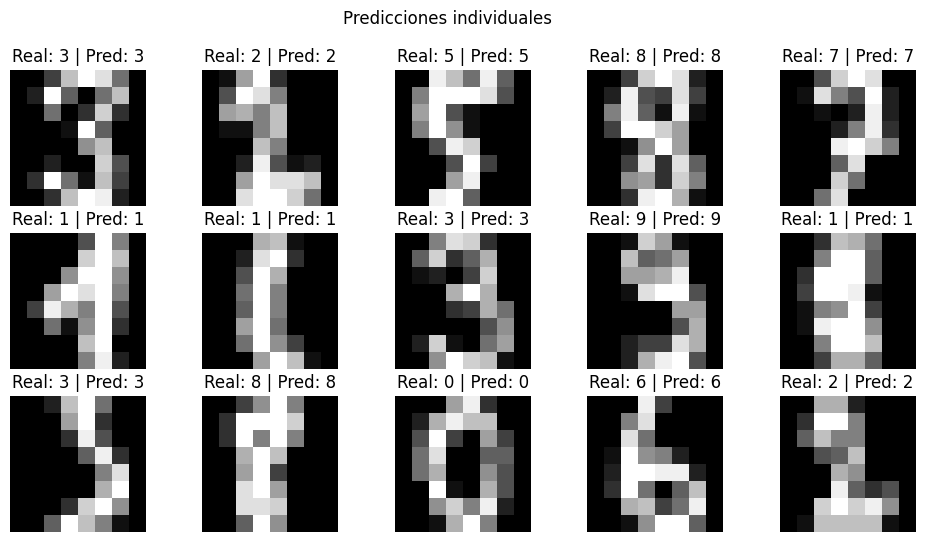

In [17]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[i].reshape(8, 8), cmap='gray')
    plt.title(f'Real: {y_test_labels[i]} | Pred: {y_pred_labels[i]}')
    plt.axis('off')

plt.suptitle('Predicciones individuales')
plt.show()

Cantidad de errores: 20


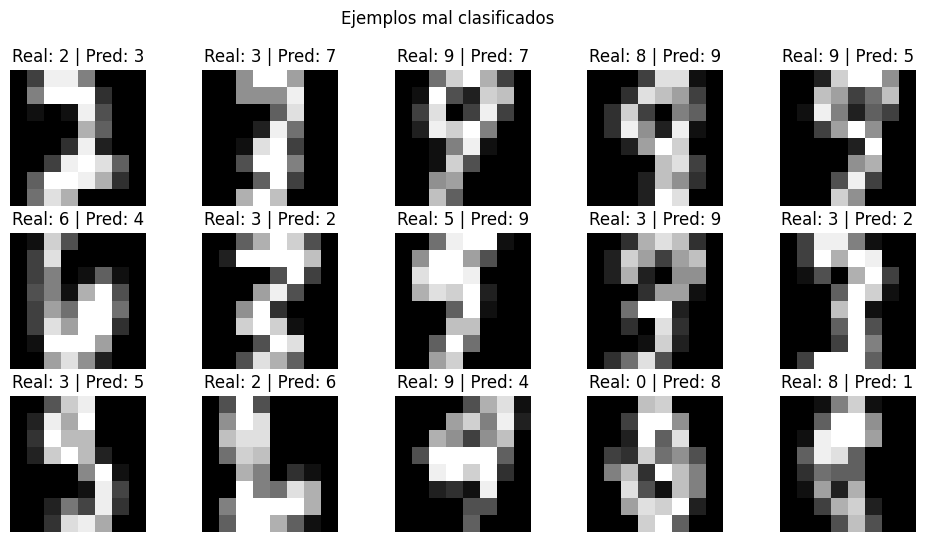

In [18]:
wrong_indices = np.where(y_test_labels != y_pred_labels)[0]

print('Cantidad de errores:', len(wrong_indices))

plt.figure(figsize=(12, 6))

for plot_index, data_index in enumerate(wrong_indices[:15]):
    plt.subplot(3, 5, plot_index + 1)
    plt.imshow(X_test[data_index].reshape(8, 8), cmap='gray')
    plt.title(f'Real: {y_test_labels[data_index]} | Pred: {y_pred_labels[data_index]}')
    plt.axis('off')

plt.suptitle('Ejemplos mal clasificados')
plt.show()

In [19]:
dense_model = Sequential([
    Flatten(input_shape=(8, 8, 1)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

dense_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

dense_history = dense_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

dense_loss, dense_accuracy = dense_model.evaluate(X_test, y_test, verbose=0)

print(f'Accuracy CNN        : {test_accuracy:.4f}')
print(f'Accuracy Dense Model: {dense_accuracy:.4f}')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Accuracy CNN        : 0.9881
Accuracy Dense Model: 0.9757


In [21]:
model.save('cnn_digits_uci.keras')
print('Modelo guardado como cnn_digits_uci.keras')

Modelo guardado como cnn_digits_uci.keras


## 24. Preguntas de análisis

Responda en su cuaderno, README o informe breve:

1. ¿Qué diferencia existe entre una red densa y una CNN?

Una red densa aplana la imagen en vector. CNN conserva la estructura de la imagen (alto x ancho).

2. ¿Qué función cumple una capa convolucional?

Extrae características de la imagen.

3. ¿Qué representa un filtro en una CNN?

Es una matriz de pesos que la red aprende mientras se entrena.

4. ¿Qué función cumple MaxPooling?

Reduce el tamaño de los mapas de características tomando el valor maximo

5. ¿Por qué normalizamos los valores de píxeles?

dado de de los valores originales son de 0 a 16. si se dividen entre 16 quedan entre 0 y 1. y eso estabiliza el calculo de los gradientes.

6. ¿Por qué usamos `softmax` en la capa de salida?

Porque es un problema multiclase. Softmax convierte salidas de red en probabilidades que suman en 1.

7. ¿Qué dígitos se confundieron más en la matriz de confusión?


8. ¿Por qué algunos dígitos escritos a mano son difíciles de clasificar?

Porque cada persona escribe diferente: varían el grosor del trazo, inclinación, el tamaño y la forma.

9. ¿Qué ventajas tendría usar imágenes de mayor resolución?

Se conservarían mas detalles del trazo, comouniones, curvas y extremos, lo que permitiría diferenciar con mejor claridad los dígitos parecidos.

10. ¿Qué limitaciones tiene este laboratorio frente a un sistema OCR real?

- Imágenes muy pequeñas (8x8)
- Solo de reconocen dígitos aislados
- etc.